# M0 and M1 on IEEE-CIS
This notebook trains M0 and M1 for logistic regression (LR), random forest (RF) and CatBoost on IEEE-CIS. Both use all candidate features and the default settings from Section 3, and M1 only adds class weights => the difference between M0 and M1 shows the effect of class weights on its own

The notebook covers:
- **M0**: LR, RF and CatBoost without class weights. Each family uses its own preprocessing (Section 3)

- **M1**: the same three models with the same preprocessing, plus class weights, so the fraud transactions count as much in total as the non-fraud transactions

- **Resampling check**: random undersampling and SMOTE in place of the class weights, to compare the common ways of handling the imbalance

- **Card history check**: we refit each M1 model without the card-history features. In IEEE-CIS, once a card has a chargeback, its later transactions are also labelled fraud, so features that recognise a card could raise the score without describing the transaction itself. The raw and reconstructed card IDs are never model inputs

- **SHAP**: SHAP values for the M1 CatBoost model

Tuning and feature selection are done after M2, so that each step from M0 to M2 only changes one thing, and the settings are tuned for the way the final model is retrained

The features come from `04_feature_engineering.ipynb` (saved in `data/processed/`). We only use the training and validation rows here. The test rows are kept aside for the final evaluation, which is run once after all choices are fixed

In [2]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from catboost import CatBoostClassifier, Pool
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)

SEED = 100
PROCESSED_DIR = Path("../data/processed")

## 1. Load the Features
We load the features and the feature lists saved by notebook 04 (run notebooks 03 and 04 first if these files are missing)
- Only the training and validation rows are kept, so the test rows never reach a model

- The model inputs are the columns in `ieee_feature_cols`. This list already leaves out the card IDs and other identifiers, which are only used to build features

- Missing values in categorical columns are replaced with the text `"missing"`, and these columns are stored as pandas categories (the models use this data type to find the categorical columns)

- `card1`, `card2`, `card3`, `card5`, `addr1` and `addr2` are stored as numbers **BUT** their values are codes (a larger number does not mean more of anything) => we turn them into text categories here, e.g. 315.0 becomes `"315"` and a missing value becomes `"missing"`, so every model gets them as categories

- Numeric columns are stored as float32

In [3]:
features = pd.read_pickle(PROCESSED_DIR / "ieee_features.pkl")
with open(PROCESSED_DIR / "feature_lists.json") as f:
    feature_lists = json.load(f)

# these columns are stored as numbers, but the numbers are codes with no order
CODE_AS_CATEGORY = ["card1", "card2", "card3", "card5", "addr1", "addr2"]

feature_cols = feature_lists["ieee_feature_cols"]
cat_cols = [c for c in feature_cols if c in feature_lists["ieee_categorical_cols"] or c in CODE_AS_CATEGORY]
num_cols = [c for c in feature_cols if c not in cat_cols]

# notebook 04 no longer builds the card1 + addr1 features, so rerun 04 if they are still in the list
old_cols = [c for c in feature_cols if "card1_addr1" in c]
if old_cols:
    raise RuntimeError(f"rerun notebook 04 first, these card1 + addr1 features are still in the feature list: {old_cols}")

# keep only the needed columns, and only the training and validation rows
keep = feature_cols + ["isFraud", "ieee_split", "TransactionDT"]
features = features.loc[features["ieee_split"].isin(["train", "validation"]), keep]
features[num_cols] = features[num_cols].astype("float32")
for col in cat_cols:
    if col in CODE_AS_CATEGORY:
        # numbers to text codes, e.g. 315.0 becomes "315" and a missing value becomes "missing"
        numbers = pd.to_numeric(features[col], errors="coerce")
        values = numbers.to_numpy(dtype="float64")
        rounded = np.round(values)
        whole = np.isfinite(values) & np.isclose(values, rounded)
        text = np.full(len(features), "missing", dtype=object)
        text[whole] = rounded[whole].astype("int64").astype(str)
        other = np.isfinite(values) & ~whole   # not a whole number => keep the value
        text[other] = numbers.to_numpy(dtype=object)[other]
        features[col] = pd.Series(text, index=features.index).astype("category")
    else:
        features[col] = features[col].astype("object").fillna("missing").astype(str).astype("category")

train = features[features["ieee_split"] == "train"]
val = features[features["ieee_split"] == "validation"]
del features

X_train, y_train = train[feature_cols], train["isFraud"]
X_val, y_val = val[feature_cols], val["isFraud"]
val_day = (val["TransactionDT"] // 86400).to_numpy()

print("training rows:", len(train), "| fraud rate:", round(y_train.mean() * 100, 2), "%")
print("validation rows:", len(val), "| fraud rate:", round(y_val.mean() * 100, 2), "% | days:", len(np.unique(val_day)))
print("features:", len(feature_cols), "| numeric:", len(num_cols), "| categorical (with the 6 code columns):", len(cat_cols))


training rows: 377945 | fraud rate: 3.41 %
validation rows: 94487 | fraud rate: 3.92 % | days: 33
features: 575 | numeric: 528 | categorical (with the 6 code columns): 47


## 2. Evaluation Metrics
All models are scored on the validation rows with the same metrics. Each model's scores are shown right after it is trained, and the full results table is in Section 7:
- **PR-AUC** (main metric): the area under the precision-recall curve, which does not depend on a threshold. A model that ranks transactions at random gets about the fraud rate, which is 0.039 on the validation rows, so this is the lowest score any model should get

- **ROC-AUC**

- **Precision, recall and F1** at a threshold of 0.5. We have not chosen a threshold yet, so 0.5 is just a default for now

- **Precision@100 per day**: for each validation day, we take the 100 transactions with the highest scores and calculate the share that are fraud, then average this over all validation days. 100 is about 3% of a day's transactions and stands for the number of cases a review team could check in one day. Note: the group has not decided yet whether k should count transactions or cards, so here it counts transactions

In [4]:
val_scores = {}   # validation scores of every model
k = 100
metric_cols = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1", f"precision@{k} per day"]


def evaluate(name):
    scores = val_scores[name]
    predictions = (scores >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()

    # precision@k per day: share of fraud among each day's k highest scores, averaged over the days
    daily = pd.DataFrame({"day": val_day, "y": y_val.to_numpy(), "score": scores})
    top_k = daily.sort_values("score", ascending=False, kind="stable").groupby("day").head(k)

    return {"model": name,
            "PR-AUC": average_precision_score(y_val, scores),
            "ROC-AUC": roc_auc_score(y_val, scores),
            "precision": precision_score(y_val, predictions, zero_division=0),
            "recall": recall_score(y_val, predictions, zero_division=0),
            "F1": f1_score(y_val, predictions, zero_division=0),
            f"precision@{k} per day": top_k.groupby("day")["y"].mean().mean(),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


# show the scores of one or more models as a table
def show(*names):
    display(pd.DataFrame([evaluate(name) for name in names]).set_index("model").round(4))

## 3. Models and Preprocessing
Each family gets the features in the form it can use. The column selectors pick the numeric and categorical columns by their data type, so the same pipeline works with any list of features. The preprocessing belongs to the family, so it is the same for M0 and M1 (they only differ in the class weights)

- **LR**: missing numeric values are filled with the training median, then we apply `arcsinh` and standardise each column. `arcsinh` works like a log for large values but is also defined at 0 and for negative values => this is important because many columns are very skewed and some `D` columns are negative. Categorical columns are one-hot encoded, and values with fewer than 100 training rows share one "infrequent" column (a weight learned from a few rows is mostly noise). The raw identity columns (e.g. `id_31`, `DeviceInfo`) are kept next to their cleaned versions (e.g. `id31_browser_family`, `device_brand`) => the cleaned ones give the general effect, and the raw ones add the effect of a specific common version or model. `card1`, `card2`, `card3`, `card5`, `addr1` and `addr2` are codes stored as categories (Section 1), so LR one-hot encodes them too. `card1` alone has about 12,000 codes => these six columns have their own one-hot encoder that only keeps codes with at least 500 training rows, and the rarer codes share one "infrequent" column

- **RF and CatBoost**: the same six code columns are given to the trees as categories, so a split can mean "this `card1` value" instead of "`card1` above 5000". The other numeric columns are used as they are, since both RF and CatBoost handle missing values themselves. RF ordinal-encodes the categorical columns: each category gets an integer learned from the training rows, missing is its own category, and a category that never appears in the training rows gets -1. CatBoost gets the categorical columns (`cat_cols`) through `cat_features` (`allow_writing_files=False` only stops CatBoost from writing log files and does not change the model)

`models` has one unfitted model per family. For each run we copy it with `clone` and only change the settings with `set_params`:
- **Class weights**: `class_weight="balanced"` for LR, `class_weight="balanced_subsample"` for RF (the weights are calculated inside each tree's bootstrap sample) and `auto_class_weights="Balanced"` for CatBoost

- **M0 and M1 settings**: `C` = 1 for LR, a minimum leaf size of 20 for RF, and depth 6 with 500 trees for CatBoost. These are common default values and are only tuned after M2

- **LR iterations**: LR is fitted with lbfgs and up to 2000 iterations. On all training rows M0 converges after about 400 iterations **BUT** M1 needs about 1,000, because the class weights make the optimisation problem harder to solve => with a limit of 1000, M1 stopped just before converging

In [5]:
numeric = make_column_selector(dtype_exclude="category")
categorical = make_column_selector(dtype_include="category")
code_pattern = r"^(?:card1|card2|card3|card5|addr1|addr2)$"
lr_codes = make_column_selector(pattern=code_pattern, dtype_include="category")   # the six code columns
lr_categorical = make_column_selector(pattern=r"^(?!(?:card1|card2|card3|card5|addr1|addr2)$)", dtype_include="category")   # all other categorical columns


# arcsinh without making another copy of the numeric columns (saves memory)
def arcsinh_in_place(X):
    return np.arcsinh(X, out=X)


models = {
    "LR": make_pipeline(
        ColumnTransformer([
            ("num", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(arcsinh_in_place), StandardScaler(copy=False)), numeric),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, dtype=np.float32), lr_categorical),   # rare values go into one column
            ("codes", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=500, dtype=np.float32), lr_codes),   # rare codes go into one column
        ]),
        LogisticRegression(max_iter=2000),   # M1 needs about 1,000 lbfgs iterations to converge on all training rows
    ),
    "RF": make_pipeline(
        ColumnTransformer([
            ("num", "passthrough", numeric),
            ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical),
        ]),
        RandomForestClassifier(n_estimators=100, max_features="sqrt", n_jobs=-1, random_state=SEED),
    ),
    "CatBoost": CatBoostClassifier(learning_rate=0.1, random_seed=SEED, thread_count=-1, verbose=0, allow_writing_files=False),
}

# M0 and M1 settings, and the setting that turns on class weights for each family
base_settings = {
    "LR": {"logisticregression__C": 1.0},
    "RF": {"randomforestclassifier__min_samples_leaf": 20},
    "CatBoost": {"depth": 6, "iterations": 500},
}
class_weight_settings = {
    "LR": {"logisticregression__class_weight": "balanced"},
    "RF": {"randomforestclassifier__class_weight": "balanced_subsample"},
    "CatBoost": {"auto_class_weights": "Balanced"},
}


## 4. M0: No Class Weights
Every transaction has the same weight, so the models learn from the training rows as they are (about 3.4% fraud). Each model is trained on all training rows with the settings from Section 3 and scored on the validation rows

### 4.1 M0 LR

In [6]:
start = time.time()
model = clone(models["LR"]).set_params(**base_settings["LR"])
model.fit(X_train, y_train)
val_scores["M0 LR"] = model.predict_proba(X_val)[:, 1]
del model
print(f"M0 LR trained in {time.time() - start:.0f}s")
show("M0 LR")

M0 LR trained in 117s


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M0 LR,0.5265,0.8876,0.7773,0.3618,0.4937,0.5282,1340,384,2364,90399


### 4.2 M0 RF

In [7]:
start = time.time()
model = clone(models["RF"]).set_params(**base_settings["RF"])
model.fit(X_train, y_train)
val_scores["M0 RF"] = model.predict_proba(X_val)[:, 1]
del model
print(f"M0 RF trained in {time.time() - start:.0f}s")
show("M0 RF")

M0 RF trained in 150s


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M0 RF,0.5591,0.9095,0.8887,0.2802,0.4261,0.5558,1038,130,2666,90653


### 4.3 M0 CatBoost

In [8]:
start = time.time()
model = clone(models["CatBoost"]).set_params(**base_settings["CatBoost"])
model.fit(X_train, y_train, cat_features=cat_cols)
val_scores["M0 CatBoost"] = model.predict_proba(X_val)[:, 1]
del model
print(f"M0 CatBoost trained in {time.time() - start:.0f}s")
show("M0 CatBoost")

M0 CatBoost trained in 777s


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M0 CatBoost,0.6255,0.9259,0.8098,0.4495,0.5781,0.6121,1665,391,2039,90392


### 4.4 M0 Results
The three M0 models side by side

In [9]:
show("M0 LR", "M0 RF", "M0 CatBoost")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M0 LR,0.5265,0.8876,0.7773,0.3618,0.4937,0.5282,1340,384,2364,90399
M0 RF,0.5591,0.9095,0.8887,0.2802,0.4261,0.5558,1038,130,2666,90653
M0 CatBoost,0.6255,0.9259,0.8098,0.4495,0.5781,0.6121,1665,391,2039,90392


**Takeaway: M0**
- **CatBoost is the best M0 model** => PR-AUC 0.626, vs 0.559 for RF and 0.527 for LR. It is also the best on ROC-AUC (0.926) and precision@100 per day (0.612, so about 61 of each day's 100 highest-scored transactions are fraud)

- All three are far above the random baseline of 0.039, so even LR with default settings ranks fraud well

- At the 0.5 threshold all three are careful: precision is high (0.78 to 0.89) **BUT** recall is low (0.28 to 0.45) => most fraud gets a score below 0.5, so 0.5 is too high as a threshold here. The threshold is chosen later, using an assumed investigation cost

- RF has the highest precision (0.889) and the lowest recall (0.280) at 0.5, so it flags the fewest transactions (1,168)

- Training time: LR 117s, RF 150s, CatBoost 777s


## 5. M1: Class Weights
Each class is weighted by the inverse of its share of the training rows => a fraud transaction counts about 28 times as much as a non-fraud transaction (the ratio of non-fraud to fraud rows in the training data). The weights only use the class imbalance, and the costs of a missed fraud or a false alarm are not part of them

Everything else (features, preprocessing and settings) is the same as M0

Note: class weights push all scores up, so precision, recall and F1 at the 0.5 threshold change even when the ranking of transactions stays the same => compare M0 and M1 on PR-AUC first

### 5.1 M1 LR

In [10]:
start = time.time()
model = clone(models["LR"]).set_params(**(base_settings["LR"] | class_weight_settings["LR"]))
model.fit(X_train, y_train)
val_scores["M1 LR"] = model.predict_proba(X_val)[:, 1]
del model
print(f"M1 LR trained in {time.time() - start:.0f}s")
show("M1 LR")

M1 LR trained in 296s


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M1 LR,0.5041,0.8878,0.1718,0.7719,0.2811,0.51,2859,13782,845,77001


### 5.2 M1 RF

In [11]:
start = time.time()
model = clone(models["RF"]).set_params(**(base_settings["RF"] | class_weight_settings["RF"]))
model.fit(X_train, y_train)
val_scores["M1 RF"] = model.predict_proba(X_val)[:, 1]
del model
print(f"M1 RF trained in {time.time() - start:.0f}s")
show("M1 RF")

M1 RF trained in 96s


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M1 RF,0.5561,0.9163,0.5332,0.5375,0.5354,0.5558,1991,1743,1713,89040


### 5.3 M1 CatBoost

In [12]:
start = time.time()
model = clone(models["CatBoost"]).set_params(**(base_settings["CatBoost"] | class_weight_settings["CatBoost"]))
model.fit(X_train, y_train, cat_features=cat_cols)
val_scores["M1 CatBoost"] = model.predict_proba(X_val)[:, 1]
shap_model = model   # kept for SHAP in Section 8
print(f"M1 CatBoost trained in {time.time() - start:.0f}s")
show("M1 CatBoost")

M1 CatBoost trained in 796s


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M1 CatBoost,0.5906,0.9219,0.3209,0.7203,0.444,0.5812,2668,5645,1036,85138


### 5.4 M0 vs M1
The three M1 models side by side, then the change from M0 to M1 for each family

In [13]:
show("M1 LR", "M1 RF", "M1 CatBoost")

# change from M0 to M1 for each family (M1 - M0)
rows = []
for family in ["LR", "RF", "CatBoost"]:
    m0, m1 = evaluate(f"M0 {family}"), evaluate(f"M1 {family}")
    rows.append({"family": family} | {metric: m1[metric] - m0[metric] for metric in metric_cols})
print("change from M0 to M1 (M1 - M0), same features, preprocessing and settings, class weights only:")
display(pd.DataFrame(rows).set_index("family").round(4))

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M1 LR,0.5041,0.8878,0.1718,0.7719,0.2811,0.5100,2859,13782,845,77001
M1 RF,0.5561,0.9163,0.5332,0.5375,0.5354,0.5558,1991,1743,1713,89040
M1 CatBoost,0.5906,0.9219,0.3209,0.7203,0.4440,0.5812,2668,5645,1036,85138


change from M0 to M1 (M1 - M0), same features, preprocessing and settings, class weights only:


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day
family,,,,,,
LR,-0.0224,0.0002,-0.6055,0.4101,-0.2127,-0.0182
RF,-0.0030,0.0068,-0.3555,0.2573,0.1093,0.0000
CatBoost,-0.0349,-0.0039,-0.4889,0.2708,-0.1341,-0.0309


**Takeaway: M1**
- **Class weights lower PR-AUC for every family**: LR 0.527 to 0.504 (-0.022), RF 0.559 to 0.556 (-0.003) and CatBoost 0.626 to 0.591 (-0.035)

- ROC-AUC barely changes (-0.004 to +0.007) => the weights mostly push all scores up instead of ranking the transactions better

- At 0.5, recall goes up a lot (LR 0.36 to 0.77, RF 0.28 to 0.54, CatBoost 0.45 to 0.72) **BUT** precision drops even more (LR 0.78 to 0.17) => M1 LR flags 16,641 transactions to catch 2,859 frauds. This comes from the scores moving past the fixed threshold, not from a better model, so we compare M0 and M1 on PR-AUC

- CatBoost loses the most. With the same 500 trees and learning rate, the weights make it focus on the fraud rows and spend less effort on telling apart the hard non-fraud rows => the top of its ranking gets worse (precision@100 per day 0.612 to 0.581). The PR curves in Section 7 show the same, with the M0 curve above M1 between recall 0.2 and 0.6

- RF is almost unchanged (-0.003 PR-AUC, same precision@100 per day)

- Note: with `max_iter=2000` both LR models now converge. M1 LR needs about 1,000 iterations (M0 LR about 400) because the weights make the optimisation problem harder to solve for lbfgs

- **Final decision**: class weights do not help the ranking on IEEE-CIS for any family

## 6. Card History Check
We refit each M1 model without the card-history features. These features do not use the labels **BUT** they can still recognise a card whose earlier behaviour was unusual, and that card's later transactions are labelled fraud after a chargeback => this check shows how much of each score depends on that

### 6.1 Feature Groups
Each feature is put in one group based on what it describes:
- The `V` columns come in blocks that are missing for the same transactions, so we group them by their missing rate on the training rows

- The raw codes `card1`, `card2`, `card3`, `card5`, `addr1` and `addr2` form their own group

- The groups are also used to add up the SHAP values per group in Section 8

The card-history groups are needed for the card history check. M0 and M1 use them like any other feature, and Section 6.2 then measures how much the M1 scores depend on them

**Card history**: features built only from earlier transactions of the same `card_id`, never from the labels. Once a card has a chargeback, its later transactions are also labelled fraud => history features can help because they recognise a card whose earlier behaviour was unusual, and not only because they describe the current transaction
- `card window`: the number and total amount of the card's transactions in the past 1 hour, 24 hours, 7 days and 30 days, and the current amount compared with the card's earlier amounts
- `card past averages`: the mean and standard deviation of earlier values on the same `card_id`, and whether a value (e.g. the email domain) is new for this card
- `card history`: the number of earlier transactions on this `card_id`, the time since the previous one, and whether `D3` matches that gap. `card_id` was partly built from `D3` in notebook 03, so the match is high for many rows by construction

**Kept in every model**, because many different cards share these keys:
- `coarse group statistics`: the mean and standard deviation of `TransactionAmt`, `D1`, `D10` and `D15` within each `card1` group, calculated on the training rows
- `coarse key history`: the number of earlier transactions and the time since the previous one, by `card1`, `addr1`, an email domain or `DeviceInfo`
- `frequency`: frequencies of single columns such as `card1`, `addr1`, the email domains, `ProductCD` and `DeviceInfo`


In [17]:
v_missing = X_train[[c for c in feature_cols if c.startswith("V") and c[1:].isdigit()]].isna().mean().round(2)

window_cols = {"is_first_txn", "amt_to_prior_mean", "amt_prior_zscore", "is_new_category"}
missing_cols = {"missing_count", "missing_fraction", "card_missing_count", "address_missing_count", "D_nonmissing_count", "D_zero_count"}
device_cols = {"DeviceType", "DeviceInfo", "device_brand", "id30_os_family", "id31_browser_family", "os_browser_pair", "has_identity",
               "screen_width", "screen_height", "screen_pixels"}
time_cols = {"hour", "minute", "seconds_in_day", "is_night", "hour_sin", "hour_cos", "day_sin", "day_cos"}

CARD_HISTORY_GROUPS = {"card window", "card past averages", "card history"}

group_of = {}
for col in feature_cols:
    if col in v_missing.index:
        group_of[col] = f"V (missing {v_missing[col]:.0%})"
    elif col in CODE_AS_CATEGORY:
        group_of[col] = "card and address codes"
    elif col.endswith("_by_card1"):
        group_of[col] = "coarse group statistics"
    elif col.endswith(("_card_past_mean", "_card_past_std", "_card_past_distinct", "_new_for_card")):
        group_of[col] = "card past averages"
    elif col.startswith(("txn_count_", "amt_sum_", "amt_mean_")) or col in window_cols:
        group_of[col] = "card window"
    elif col in {"card_id_previous_count", "card_id_seconds_since_previous"} or col.startswith(("D3_gap", "D3_matches")):
        group_of[col] = "card history"
    elif col.endswith(("_previous_count", "_seconds_since_previous")):
        group_of[col] = "coarse key history"
    elif col.endswith("_freq"):
        group_of[col] = "frequency"
    elif col in missing_cols or col.endswith(("missing_count", "missing_fraction", "_missing")):
        group_of[col] = "missingness"
    elif col.startswith("C") and col[1:].isdigit():
        group_of[col] = "C"
    elif (col.startswith("D") and col[1:].isdigit()) or col == "D3_log1p":
        group_of[col] = "D"
    elif col.startswith("M") and col[1:].isdigit():
        group_of[col] = "M"
    elif col.startswith("id_"):
        group_of[col] = "identity id_"
    elif col in device_cols or col.startswith("deviceinfo_"):
        group_of[col] = "device"
    elif "emaildomain" in col or col == "email_domain_match":
        group_of[col] = "email"
    elif col.startswith("card"):
        group_of[col] = "card"
    elif col.startswith(("addr", "dist", "address")):
        group_of[col] = "address"
    elif col.startswith(("TransactionAmt", "amount")):
        group_of[col] = "amount"
    elif col in time_cols:
        group_of[col] = "time"
    elif col == "ProductCD":
        group_of[col] = "product"
    else:
        group_of[col] = "other"

# role of each group (all other groups are "transaction-level")
group_role = {group: "card history" for group in CARD_HISTORY_GROUPS}
group_role["coarse group statistics"] = "coarse entity aggregate"
group_role["coarse key history"] = "coarse entity aggregate"

roles = pd.Series(group_of)
summary = pd.DataFrame({"group": roles, "role": [group_role.get(g, "transaction-level") for g in roles]})
display(summary.groupby(["role", "group"]).size().rename("features").to_frame())

# make sure no card-history or card ID column ends up in "other"
other_cols = [c for c, g in group_of.items() if g == "other"]
print("columns in 'other':", other_cols)
missed = [c for c in other_cols if "card_id" in c or c.startswith("D3_") or "card_past" in c or c.endswith("_by_card1")]
if missed:
    raise RuntimeError(f"card-history or card-id columns were not classified: {missed}")

features
role                    group                            
card history            card history                    4
                        card past averages             37
                        card window                    16
coarse entity aggregate coarse group statistics         8
                        coarse key history             10
transaction-level       C                              14
                        D                              16
                        M                               9
                        V (missing 0%)                 86
                        V (missing 16%)                45
                        V (missing 18%)                20
                        V (missing 31%)                18
                        V (missing 57%)                11
                        V (missing 73%)                16
                        V (missing 74%)                50
                        V (missing 75%)                46
                        V (missing 83%)                47
                        address                         3
                        amount                          5
                        card                            3
                        card and address codes          6
                        device                         14
                        email                           7
                        frequency                      16
                        identity id_                   38
                        missingness                    21
                        product                         1
                        time                            8

columns in 'other': []


### 6.2 M1 Without Card History
For each family, we use the M1 settings and refit on all training rows without the card-history groups, then compare with the M1 model from Section 5 (all candidate features)

The coarse `card1` statistics and the history by email domain, `DeviceInfo` and `addr1` stay in, because many cards share those keys


In [18]:
no_history_cols = [c for c in feature_cols if group_of[c] not in CARD_HISTORY_GROUPS]
no_history_cats = [c for c in cat_cols if c in no_history_cols]
print(f"all candidate features: {len(feature_cols)} | without card history: {len(no_history_cols)}")

for family in ["LR", "RF", "CatBoost"]:
    start = time.time()
    model = clone(models[family]).set_params(**(base_settings[family] | class_weight_settings[family]))
    if family == "CatBoost":
        model.fit(X_train[no_history_cols], y_train, cat_features=no_history_cats)
    else:
        model.fit(X_train[no_history_cols], y_train)
    name = f"M1 {family}, no card history"
    val_scores[name] = model.predict_proba(X_val[no_history_cols])[:, 1]
    del model
    print(f"{name}: PR-AUC {average_precision_score(y_val, val_scores[name]):.4f} ({time.time() - start:.0f}s)")


all candidate features: 575 | without card history: 518
M1 LR, no card history: PR-AUC 0.5089 (253s)
M1 RF, no card history: PR-AUC 0.5600 (85s)
M1 CatBoost, no card history: PR-AUC 0.5918 (803s)


In [19]:
# each M1 model, then the same model without the card-history features
show(*[f"M1 {family}{suffix}" for family in ["LR", "RF", "CatBoost"] for suffix in ["", ", no card history"]])


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M1 LR,0.5041,0.8878,0.1718,0.7719,0.2811,0.5100,2859,13782,845,77001
"M1 LR, no card history",0.5089,0.8881,0.1722,0.7724,0.2816,0.5152,2861,13756,843,77027
M1 RF,0.5561,0.9163,0.5332,0.5375,0.5354,0.5558,1991,1743,1713,89040
"M1 RF, no card history",0.5600,0.9177,0.5097,0.5559,0.5318,0.5491,2059,1981,1645,88802
M1 CatBoost,0.5906,0.9219,0.3209,0.7203,0.4440,0.5812,2668,5645,1036,85138
"M1 CatBoost, no card history",0.5918,0.9196,0.3474,0.7036,0.4651,0.5879,2606,4896,1098,85887


**Takeaway: Card History Check**
- Removing the 57 card-history features barely changes PR-AUC: LR 0.504 to 0.509 (+0.005), RF 0.556 to 0.560 (+0.004) and CatBoost 0.591 to 0.592 (+0.001). Precision@100 per day also moves by less than 0.01 (RF -0.007, CatBoost +0.007) => The M1 models do not depend on recognising the card, which is what we wanted to check, since a card's later transactions are labelled fraud after a chargeback

- **BUT** this does not mean the models ignore these features. In Section 8 the `card past averages` group is still the 5th largest group by total |SHAP| => when the card-history features are removed, other features (e.g. the `C` counts, `D` columns and the coarse `card1` history) seem to carry the same information

- Note: these differences are small and could be due to seed nouse, so we do not read more into them

## 7. Validation Results
All models together. PR-AUC is the main metric. Precision, recall and F1 use the 0.5 threshold, so they change when class weights shift the scores, even if the ranking of transactions stays the same. Precision@100 per day is the share of fraud among each day's 100 highest-scored transactions, averaged over the validation days

The M0 and M1 rows use all candidate features and the settings from Section 3. The undersampling and SMOTE rows use the same settings with resampled training rows instead of class weights (Section 5.5). The card history rows are the M1 models refitted without those features (Section 6)

In [20]:
results_table = pd.DataFrame([evaluate(name) for name in val_scores]).set_index("model")
display(results_table.round(4))

print("family ranking by validation PR-AUC:")
for title, stage, suffix in [("M0", "M0", ""), ("M1", "M1", ""),
                             ("M1 without card history", "M1", ", no card history")]:
    ranking = sorted(["LR", "RF", "CatBoost"], key=lambda family: results_table.loc[f"{stage} {family}{suffix}", "PR-AUC"], reverse=True)
    bits = ", ".join(f"{family} {results_table.loc[f'{stage} {family}{suffix}', 'PR-AUC']:.4f}" for family in ranking)
    print(f"  {title}: {bits}")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M0 LR,0.5265,0.8876,0.7773,0.3618,0.4937,0.5282,1340,384,2364,90399
M0 RF,0.5591,0.9095,0.8887,0.2802,0.4261,0.5558,1038,130,2666,90653
M0 CatBoost,0.6255,0.9259,0.8098,0.4495,0.5781,0.6121,1665,391,2039,90392
M1 LR,0.5041,0.8878,0.1718,0.7719,0.2811,0.5100,2859,13782,845,77001
M1 RF,0.5561,0.9163,0.5332,0.5375,0.5354,0.5558,1991,1743,1713,89040
M1 CatBoost,0.5906,0.9219,0.3209,0.7203,0.4440,0.5812,2668,5645,1036,85138
"M1 LR, undersampling",0.5030,0.8849,0.1507,0.7870,0.2530,0.5121,2915,16429,789,74354
"M1 RF, undersampling",0.5216,0.8985,0.1726,0.7851,0.2830,0.5306,2908,13938,796,76845
"M1 CatBoost, undersampling",0.5958,0.9273,0.2397,0.7827,0.3670,0.5830,2899,9196,805,81587


family ranking by validation PR-AUC:
  M0: CatBoost 0.6255, RF 0.5591, LR 0.5265
  M1: CatBoost 0.5906, RF 0.5561, LR 0.5041
  M1 without card history: CatBoost 0.5918, RF 0.5600, LR 0.5089


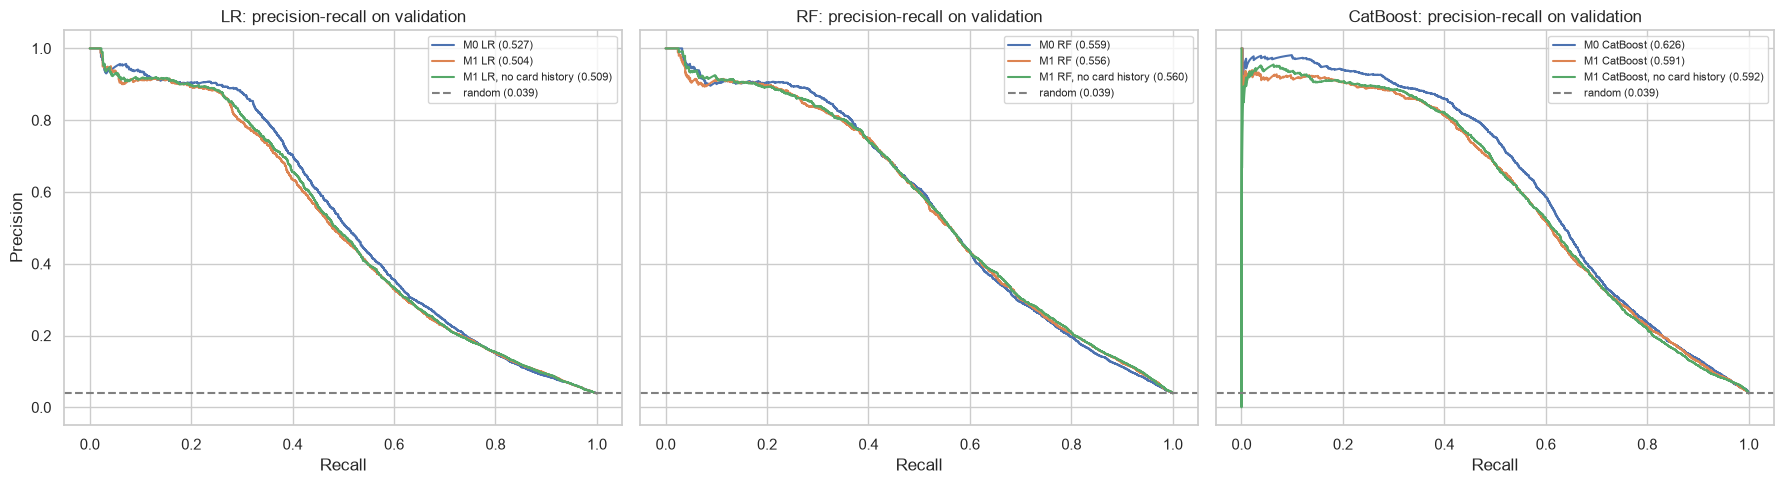

In [21]:
# precision-recall curves on the validation rows
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

curve_names = [
    "M0 {family}",
    "M1 {family}",
    "M1 {family}, no card history",
]
for ax, family in zip(axes, ["LR", "RF", "CatBoost"]):
    for pattern in curve_names:
        name = pattern.format(family=family)
        precision, recall, thresholds = precision_recall_curve(y_val, val_scores[name])
        ax.plot(recall, precision, label=f"{name} ({results_table.loc[name, 'PR-AUC']:.3f})")

    # a model that ranks at random gets the fraud rate
    ax.axhline(y_val.mean(), color="grey", linestyle="--", label=f"random ({y_val.mean():.3f})")
    ax.set_title(f"{family}: precision-recall on validation")
    ax.set_xlabel("Recall")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Precision")
plt.tight_layout()
plt.show()

**Takeaway: Validation Results**
- The family ranking is the same for M0, M1 and M1 without card history => CatBoost, then RF, then LR

- The best model so far is **M0 CatBoost** (PR-AUC 0.626, ROC-AUC 0.926, precision@100 per day 0.612)

- CatBoost is ahead of RF by 0.067 PR-AUC in M0 and 0.035 in M1. Both gaps are larger than seed noise (NEED TO EXPERIMENT TO CHECK, but based on google it seems to be above seed noise), so CatBoost being the strongest family is not just noise. RF is ahead of LR by 0.03 to 0.05

- In the PR curves, all models keep a precision of about 0.9 up to a recall of about 0.2, so the easiest frauds are found by every model. The families mostly differ between recall 0.3 and 0.6. Above a recall of about 0.8 all curves drop to a precision of about 0.1 to 0.2 => the hardest frauds look normal to every model

- Note: these results come from one validation split and one seed, and the settings are not tuned. The final family choice for M3 and M4 is made after M2

## 8. SHAP Values for the M1 CatBoost Model
SHAP values split each prediction into a contribution from each feature, and a positive value pushes the score towards fraud. We calculate them with CatBoost's built-in SHAP for 5,000 random validation transactions and show:
- The features with the largest mean absolute SHAP value (the features the model relies on most)
- The total mean absolute SHAP value per feature group (groups from Section 6.1)
- The direction of each numeric feature: the Spearman correlation between its value and its SHAP value (positive => higher values push the score towards fraud)

Note: SHAP only describes what this fitted model uses. It does not show whether a feature generalises to later data, so we do not use it to select features. If card-history features rank high here, the model partly relies on recognising the card (Section 6.2 measures how much the score depends on that)

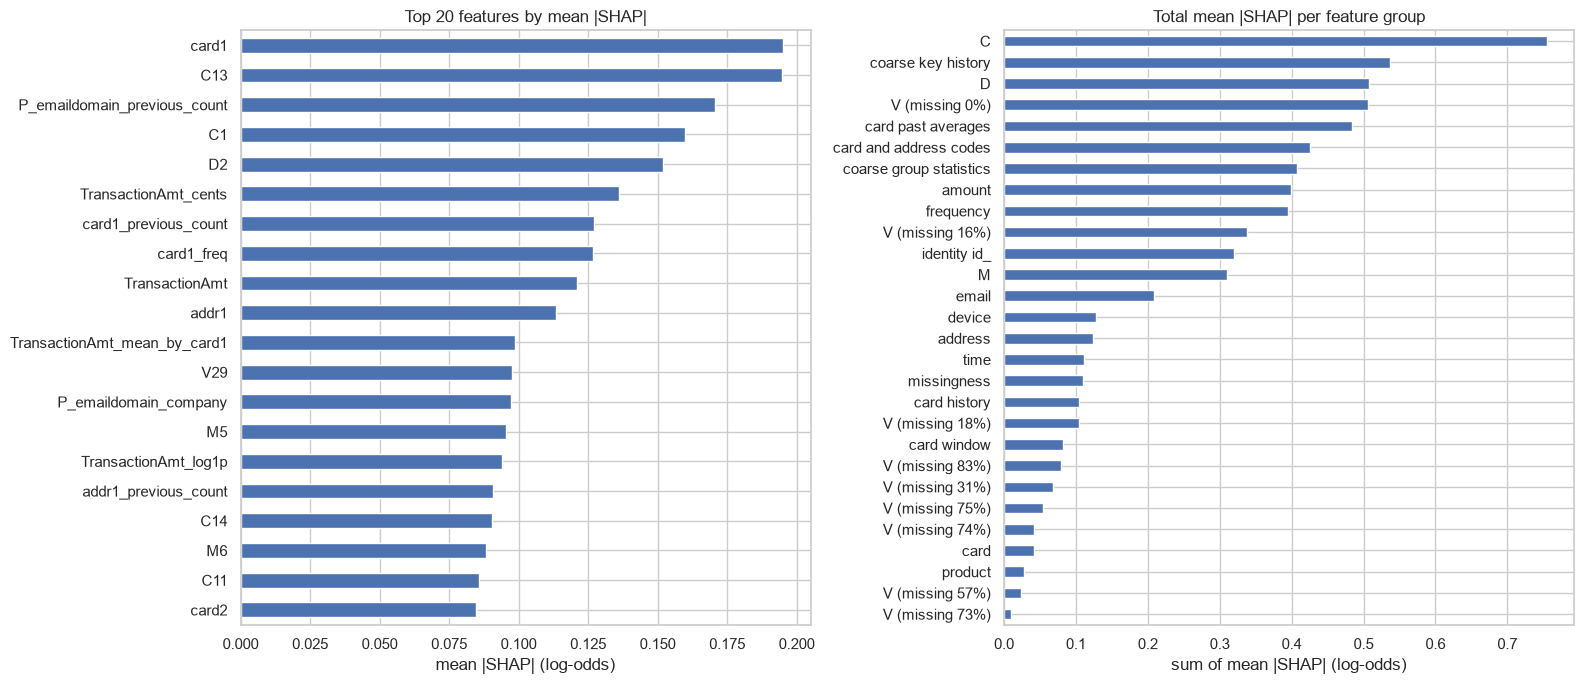

,group,role,mean |SHAP|,value vs SHAP (Spearman)
card1,card and address codes,transaction-level,0.195,NaN
C13,C,transaction-level,0.195,-0.962
P_emaildomain_previous_count,coarse key history,coarse entity aggregate,0.171,-0.075
C1,C,transaction-level,0.160,0.749
D2,D,transaction-level,0.152,-0.833
TransactionAmt_cents,amount,transaction-level,0.136,-0.789
card1_previous_count,coarse key history,coarse entity aggregate,0.127,0.621
card1_freq,frequency,transaction-level,0.127,0.599
TransactionAmt,amount,transaction-level,0.121,0.917
addr1,card and address codes,transaction-level,0.113,NaN


In [22]:
shap_cols = feature_cols   # M1 uses all candidate features
shap_rows = X_val[shap_cols].sample(5000, random_state=SEED)
shap_values = shap_model.get_feature_importance(Pool(shap_rows, cat_features=cat_cols), type="ShapValues")[:, :-1]
shap_values = pd.DataFrame(shap_values, index=shap_rows.index, columns=shap_cols)

mean_abs = shap_values.abs().mean().sort_values(ascending=False)
group_abs = mean_abs.groupby(pd.Series(group_of)).sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
mean_abs.head(20).iloc[::-1].plot.barh(ax=axes[0])
axes[0].set_title("Top 20 features by mean |SHAP|")
axes[0].set_xlabel("mean |SHAP| (log-odds)")
group_abs.iloc[::-1].plot.barh(ax=axes[1])
axes[1].set_title("Total mean |SHAP| per feature group")
axes[1].set_xlabel("sum of mean |SHAP| (log-odds)")
plt.tight_layout()
plt.show()

# top 20 features by mean |SHAP|, with their group and direction (categorical features have no direction)
top_shap = mean_abs.head(20).rename("mean |SHAP|").to_frame()
top_shap.insert(0, "group", [group_of[c] for c in top_shap.index])
top_shap.insert(1, "role", [group_role.get(group_of[c], "transaction-level") for c in top_shap.index])
top_shap["value vs SHAP (Spearman)"] = [
    pd.Series(shap_rows[c].to_numpy(), dtype="float64").corr(pd.Series(shap_values[c].to_numpy()), method="spearman")
    if c not in cat_cols else np.nan
    for c in top_shap.index
]
display(top_shap.round(3))

**Takeaway: SHAP**
- The features M1 CatBoost relies on most are `card1` and `C13` (mean |SHAP| 0.195 each), then `P_emaildomain_previous_count` (0.171), `C1` (0.160) and `D2` (0.152). By group, the `C` counts are the largest by far (about 0.76), followed by the coarse key history, `D`, `V (missing 0%)` and the card past averages

- Directions of the numeric features:
    - larger amounts push the score towards fraud (`TransactionAmt` 0.92), and so do higher `C1` and `C11` (0.75 and 0.83)
    - higher `C13`, `C14` and `V29` push it away from fraud (-0.96, -0.80 and -0.84)
    - a lower `D2` pushes towards fraud (-0.83). `D2` is almost the same as `D1` (Spearman 0.98 in notebook 04), which looks like the days since the card was first used => newer cards look riskier
    - `TransactionAmt_cents` has -0.79 => amounts with fewer cents (e.g. round amounts) push towards fraud

- The raw codes `card1`, `addr1` and `card2` are in the top 20 => the model uses how risky a specific code is. Many cards share each code, so this is not the same as recognising one card **BUT** the risk of a code can change over time (e.g. if fraud moves to other card types), which M2 will show

- No card-history feature is in the top 20. They are spread over 57 features, so they only show up when added up per group, which matches Section 6 (removing them barely changes the score)

- Note: SHAP only shows what this fitted model uses, not whether a feature still works on later data
